Correlation matrix:
[[1.         0.79075079]
 [0.79075079 1.        ]]


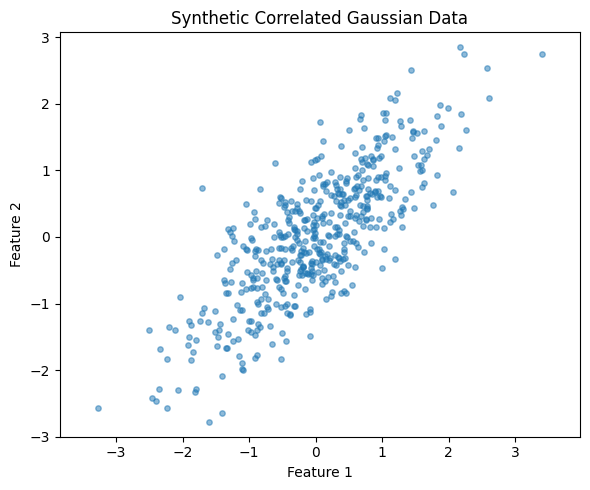


Covariance matrix:
[[0.92486292 0.74324047]
 [0.74324047 0.95521704]]

Eigenvalues (largest first):
[1.68343539 0.19664457]

Principal component directions (columns):
[[ 0.69985146 -0.71428841]
 [ 0.71428841  0.69985146]]

Proportion of variance explained:
PC1: 0.8954 (89.54%)
PC2: 0.1046 (10.46%)


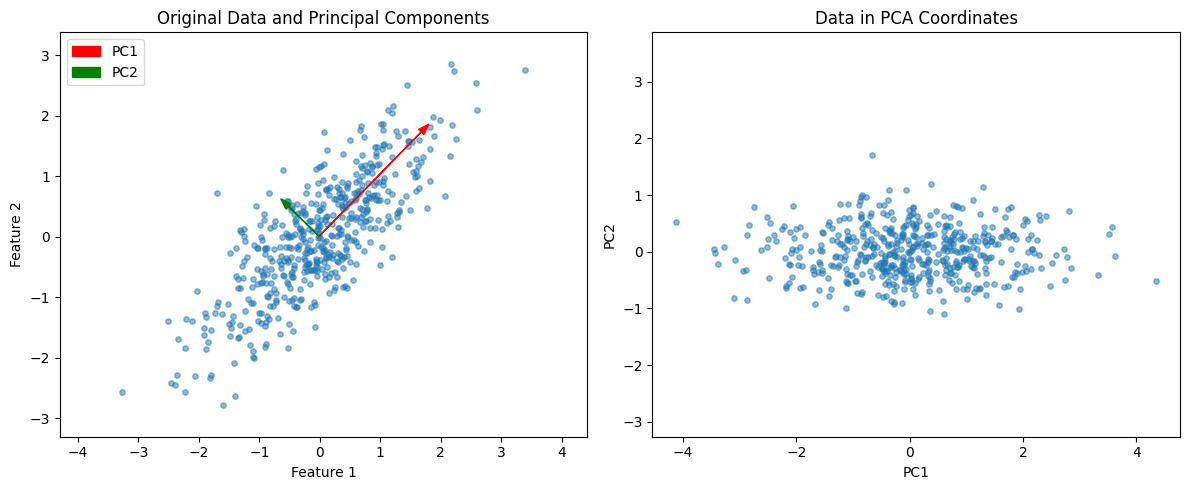

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Q2 - generating the synthetic 2-dimensional dataset composed of two correlated Gaussian features
np.random.seed(42)
mean = [0, 0]
cov = [[1, 0.8],
       [0.8, 1]]

X = np.random.multivariate_normal(mean, cov, 500)

print("Correlation matrix:")
print(np.corrcoef(X.T))

# get the scatter plot of the dataset
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], alpha=0.5, s=15)
plt.title("Synthetic Correlated Gaussian Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.axis("equal")
plt.tight_layout()
plt.savefig("q2_scatter.png", dpi=150)
plt.show()


# Q3 - implementing PCA

# center the dataset (mean subtraction)
X_centered = X - np.mean(X, axis=0)

# compute covariance matrix
n = X_centered.shape[0]
Sigma = (X_centered.T @ X_centered) / (n - 1)

# get the eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

# sort by the decreasing eigenvalue in order to select the PCs corresponding to the highest eigenvalues
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# project the data onto the PCs
X_pca = X_centered @ eigenvectors

print("\nCovariance matrix:")
print(Sigma)

print("\nEigenvalues (largest first):")
print(eigenvalues)

print("\nPrincipal component directions (columns):")
print(eigenvectors)

# Q4 - proportion of variance
explained_variance = eigenvalues / np.sum(eigenvalues)
print("\nProportion of variance explained:")
for i, ratio in enumerate(explained_variance):
    print(f"PC{i+1}: {ratio:.4f} ({ratio*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# see the original data with principal component directions
axes[0].scatter(X[:, 0], X[:, 1], alpha=0.5, s=15)
origin = np.mean(X, axis=0)

for i in range(2):
    direction = eigenvectors[:, i] * 2 * np.sqrt(eigenvalues[i])
    axes[0].arrow(
        origin[0], origin[1],
        direction[0], direction[1],
        head_width=0.12, length_includes_head=True,
        color="red" if i == 0 else "green",
        label=f"PC{i+1}"
    )

axes[0].set_title("Original Data and Principal Components")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].axis("equal")
axes[0].legend()

# see the data after projection into PCA coordinates
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.5, s=15)
axes[1].set_title("Data in PCA Coordinates")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].axis("equal")

plt.tight_layout()
plt.savefig("q3_pca.png", dpi=150)
plt.show()